# De la donnée à la décision — Statistiques pour les Experts Data

## TP 04 — Séries temporelles

**Auteur :** Bassem Ben Hamed — `bassem.benhamed@enetcom.usf.tn`

**Contenu :** Modules 11 à 15 de la formation (Partie 4 — Séries temporelles).

**Dataset fil rouge :** *Pharmaceutical Sales Data* (Kaggle / Milan Zdravković).

Ce notebook accompagne le module 04 Séries temporelles. Format inchangé :
1. **Rappel théorique** (formule + intuition).
2. **Code commenté** en français.
3. **Interprétation business** systématique.

> Les bibliothèques `prophet` et `pmdarima` sont requises :
> ```
> pip install prophet pmdarima
> ```

## Sommaire

- **Setup** — imports, chargement des données journalières et mensuelles
- **Module 11** — Spécificités des séries temporelles
  - Composantes (tendance, saisonnalité, bruit)
  - Décomposition additive vs multiplicative
- **Module 12** — Préparation
  - Resampling, valeurs manquantes
  - Moyennes mobiles, EWMA
  - Visualisations (saisonnier, lag plot, heatmap)
- **Module 13** — Stationnarité & autocorrélation
  - Tests ADF et KPSS
  - Différenciation
  - ACF / PACF
- **Module 14** — Modèles de prévision
  - Baselines (naïve, naïve saisonnière, moyenne)
  - Holt-Winters
  - SARIMA (manuel + `auto_arima`)
  - Prophet
  - Comparaison SARIMA vs Prophet
  - Backtesting rolling origin
  - Métriques (MAE, RMSE, MAPE, sMAPE)
  - Intervalles de prédiction
- **Module 15** — Détection d'anomalies
  - Z-score sur fenêtre roulante
  - STL + détection sur résidus
- **Synthèse**

## Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')
import logging
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from statsmodels.tsa.seasonal       import seasonal_decompose, STL
from statsmodels.tsa.stattools      import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots  import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters    import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm
from prophet import Prophet

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.titlesize'] = 12
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

### Chargement du dataset

On utilise deux granularités :
- **Journalière** (`salesdaily.csv`) — pour l'exploration, les ACF/PACF, la détection d'anomalies.
- **Mensuelle** (`salesmonthly.csv`) — pour les modèles de prévision (saisonnalité annuelle $s = 12$).

In [2]:
csv_d = Path('dataset') / 'salesdaily.csv'
csv_m = Path('dataset') / 'salesmonthly.csv'

df_d = (pd.read_csv(csv_d, parse_dates=['datum'])
        .rename(columns={'datum': 'date'})
        .set_index('date')
        .sort_index())

df_m = (pd.read_csv(csv_m, parse_dates=['datum'])
        .rename(columns={'datum': 'date'})
        .set_index('date')
        .sort_index())

categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
df_d = df_d[categories]
df_m = df_m[categories]

# Régler la fréquence mensuelle (mois fin de période)
df_m = df_m.asfreq('ME')

print(f'Journalier : {df_d.shape}, du {df_d.index.min().date()} au {df_d.index.max().date()}')
print(f'Mensuel    : {df_m.shape}, du {df_m.index.min().date()} au {df_m.index.max().date()}')

Journalier : (2106, 8), du 2014-01-02 au 2019-10-08
Mensuel    : (70, 8), du 2014-01-31 au 2019-10-31


**Catégorie fil rouge :** `R06` (antihistaminiques) — saisonnalité annuelle très claire (pic au printemps).

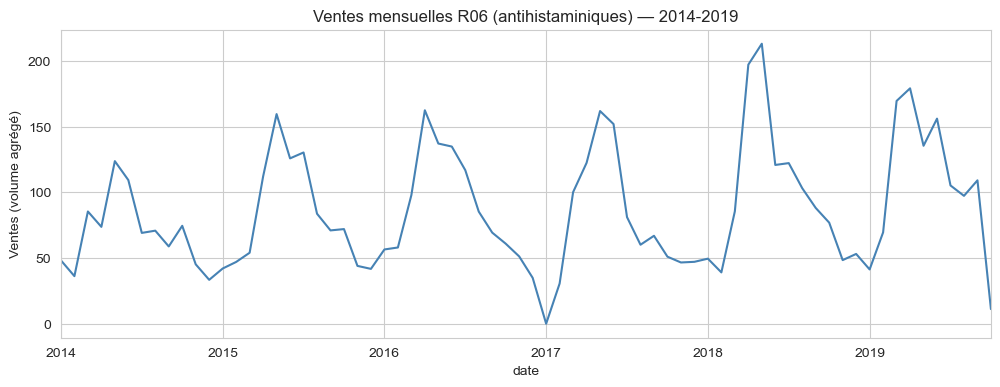

In [3]:
y = df_m['R06'].copy()
y.name = 'R06'

fig, ax = plt.subplots(figsize=(12, 4))
y.plot(ax=ax, color='steelblue', lw=1.5)
ax.set_title('Ventes mensuelles R06 (antihistaminiques) — 2014-2019')
ax.set_ylabel('Ventes (volume agrégé)')
plt.show()

**Lecture :** la saisonnalité annuelle saute aux yeux. Pic autour du printemps (avril-mai), creux en hiver. Tendance globale assez stable. C'est la série idéale pour démontrer SARIMA et Prophet.

---
## Module 11 — Spécificités des séries temporelles

### 11.1 Décomposition additive

$$Y_t = T_t + S_t + R_t$$

- $T_t$ : tendance
- $S_t$ : saisonnalité
- $R_t$ : résidu (bruit)

On utilise `seasonal_decompose` (`statsmodels`) qui calcule une moyenne mobile pour la tendance puis isole la saisonnalité.

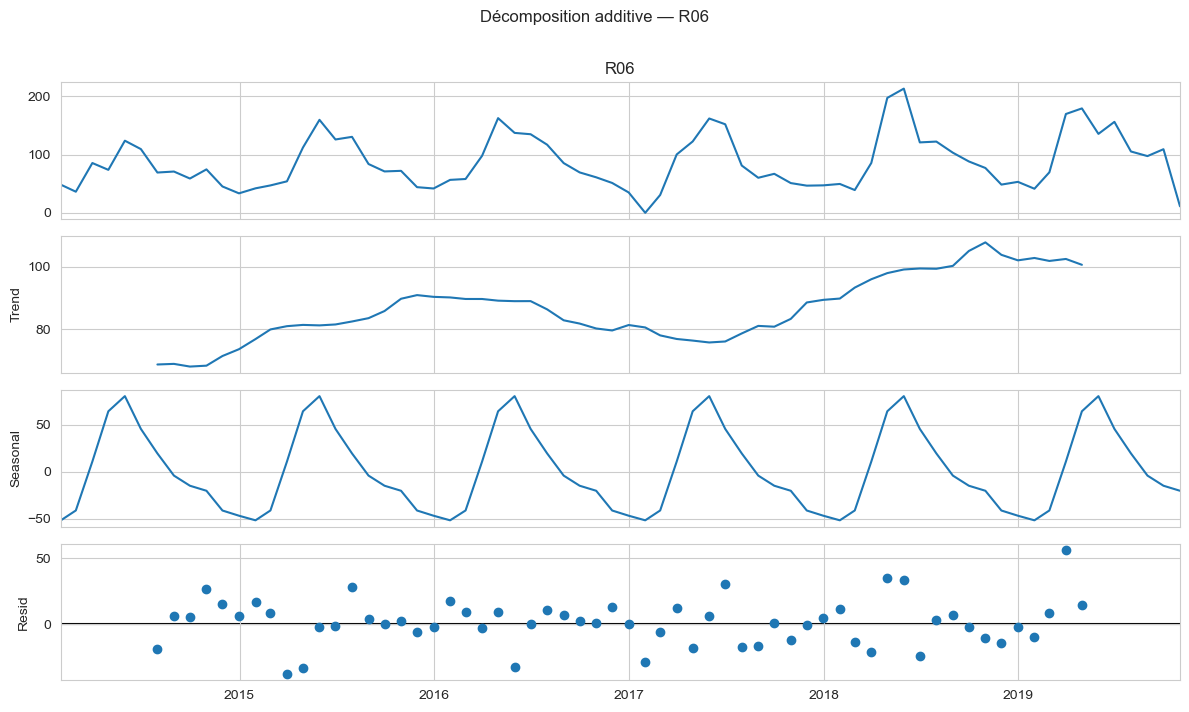

In [4]:
decomp_add = seasonal_decompose(y, model='additive', period=12)
fig = decomp_add.plot()
fig.set_size_inches(12, 7)
plt.suptitle('Décomposition additive — R06', y=1.01)
plt.tight_layout(); plt.show()

**Lecture :**
- Le panneau **Trend** montre l'évolution lissée de la tendance.
- Le panneau **Seasonal** isole le motif annuel (pic printemps).
- Le panneau **Resid** contient ce qui n'est expliqué ni par la tendance ni par la saisonnalité — c'est sur lui qu'on cherchera des anomalies (Module 15).

### 11.2 Additif vs multiplicatif

$$Y_t = T_t \cdot S_t \cdot R_t$$

**Quand préférer le multiplicatif :** quand l'amplitude des oscillations grandit avec le niveau. Test rapide : passer en log et voir si la décomposition devient plus régulière.

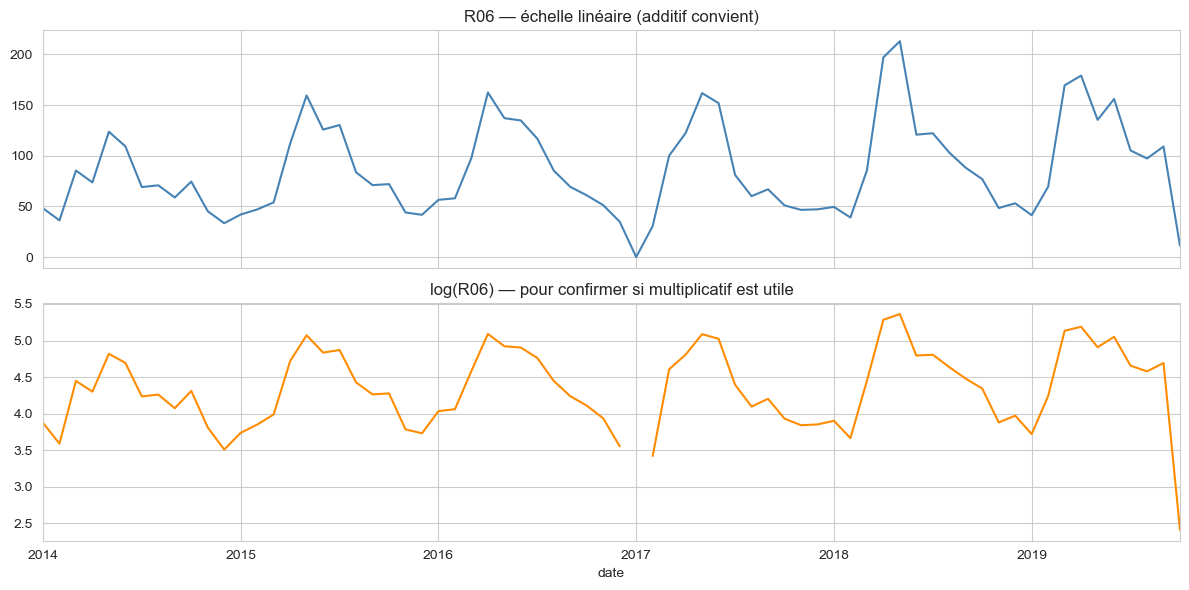

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
y.plot(ax=axes[0], color='steelblue')
axes[0].set_title('R06 — échelle linéaire (additif convient)')
np.log(y).plot(ax=axes[1], color='darkorange')
axes[1].set_title('log(R06) — pour confirmer si multiplicatif est utile')
plt.tight_layout(); plt.show()

**Interprétation :** sur R06, les amplitudes saisonnières restent assez stables au fil des années → décomposition **additive** suffit. Pour des séries où le pic grandit chaque année (par ex. trafic web en croissance), passer au multiplicatif (`model='multiplicative'`) ou prendre le log.

---
## Module 12 — Exploration et préparation

### 12.1 Resampling — passer de daily à monthly/weekly

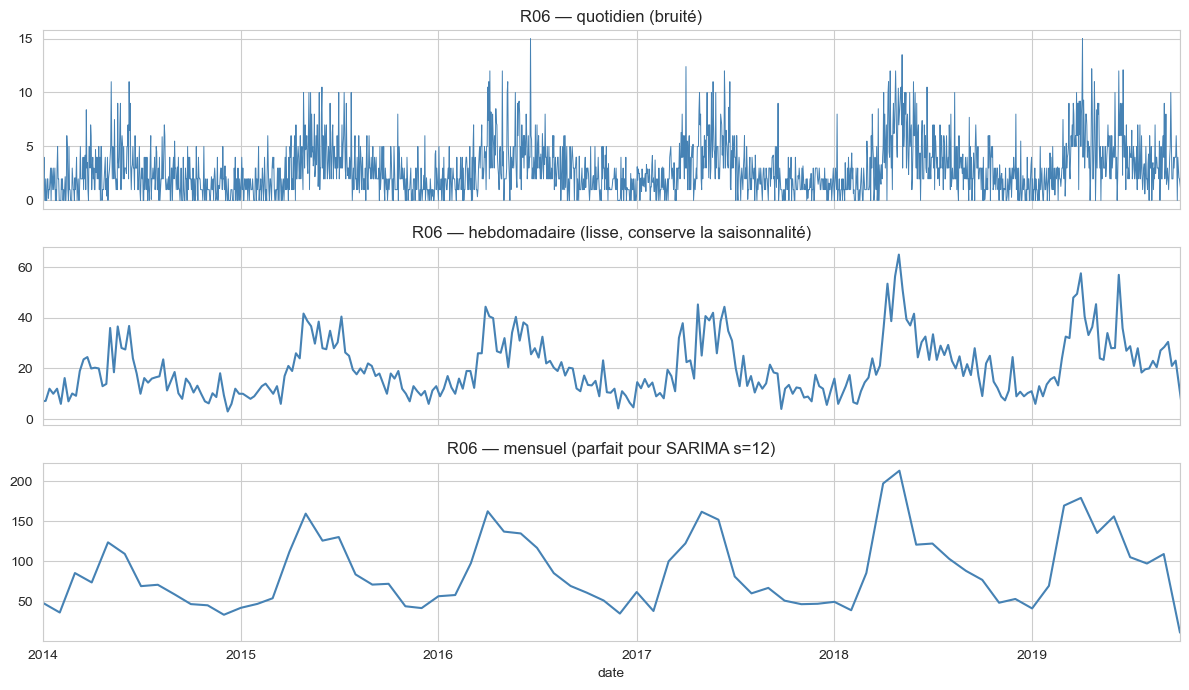

In [6]:
# Repasser de la journée à la semaine et au mois
weekly  = df_d['R06'].resample('W').sum()
monthly = df_d['R06'].resample('ME').sum()

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
df_d['R06'].plot(ax=axes[0], color='steelblue', lw=0.7)
axes[0].set_title('R06 — quotidien (bruité)')
weekly.plot(ax=axes[1], color='steelblue')
axes[1].set_title('R06 — hebdomadaire (lisse, conserve la saisonnalité)')
monthly.plot(ax=axes[2], color='steelblue')
axes[2].set_title('R06 — mensuel (parfait pour SARIMA s=12)')
plt.tight_layout(); plt.show()

**Choix de la granularité :** dépend de l'horizon de prévision et de la nature de la saisonnalité. Pour prévoir 6-12 mois à l'avance, le mensuel suffit largement et simplifie SARIMA.

### 12.2 Moyenne mobile (rolling)

$$\mathrm{MA}_t^{(k)} = \frac{1}{k}\sum_{i=0}^{k-1} Y_{t-i}$$

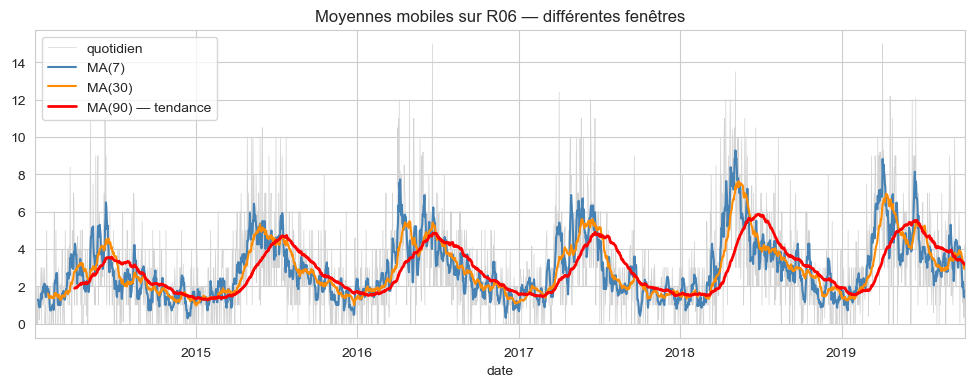

In [7]:
x = df_d['R06']
ma_7  = x.rolling(window=7).mean()
ma_30 = x.rolling(window=30).mean()
ma_90 = x.rolling(window=90).mean()

fig, ax = plt.subplots(figsize=(12, 4))
x.plot(ax=ax, color='lightgray', lw=0.5, label='quotidien')
ma_7.plot(ax=ax,  color='steelblue', label='MA(7)')
ma_30.plot(ax=ax, color='darkorange', label='MA(30)')
ma_90.plot(ax=ax, color='red', lw=2, label='MA(90) — tendance')
ax.set_title('Moyennes mobiles sur R06 — différentes fenêtres')
ax.legend(); plt.show()

**Interprétation :** plus la fenêtre est grande, plus on lisse mais plus on perd en réactivité. MA(7) supprime l'effet jour de la semaine. MA(30) lisse le bruit court-terme. MA(90) révèle la tendance.

### 12.3 EWMA (moyenne mobile exponentielle)

$$\tilde{Y}_t = \alpha Y_t + (1-\alpha) \tilde{Y}_{t-1}, \quad \alpha \in (0, 1]$$

Pondération exponentiellement décroissante sur le passé. Plus $\alpha$ est grand, plus on est réactif.

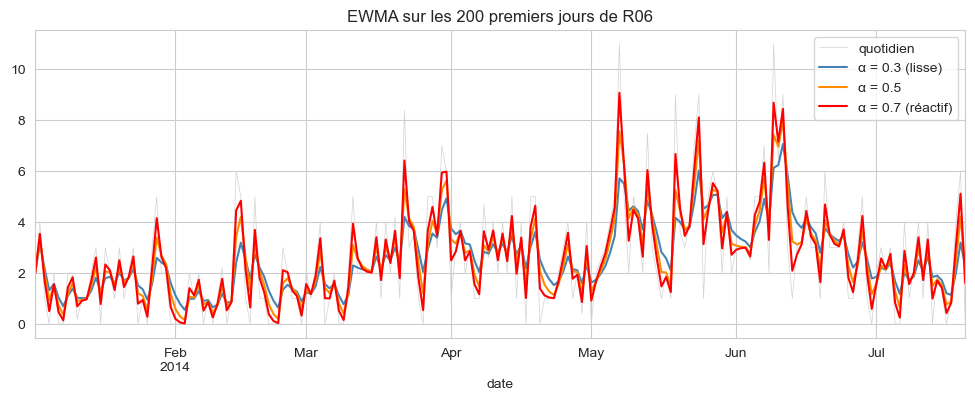

In [8]:
ewma_03 = x.ewm(alpha=0.3).mean()
ewma_05 = x.ewm(alpha=0.5).mean()
ewma_07 = x.ewm(alpha=0.7).mean()

fig, ax = plt.subplots(figsize=(12, 4))
x.iloc[:200].plot(ax=ax, color='lightgray', lw=0.5, label='quotidien')
ewma_03.iloc[:200].plot(ax=ax, color='steelblue', label='α = 0.3 (lisse)')
ewma_05.iloc[:200].plot(ax=ax, color='darkorange', label='α = 0.5')
ewma_07.iloc[:200].plot(ax=ax, color='red', label='α = 0.7 (réactif)')
ax.set_title('EWMA sur les 200 premiers jours de R06')
ax.legend(); plt.show()

**À retenir :** le choix entre `rolling` et `ewm` dépend du compromis recherché entre lissage uniforme (rolling) et adaptation rapide aux récents (ewm).

### 12.4 Visualisation saisonnière — un pattern par année

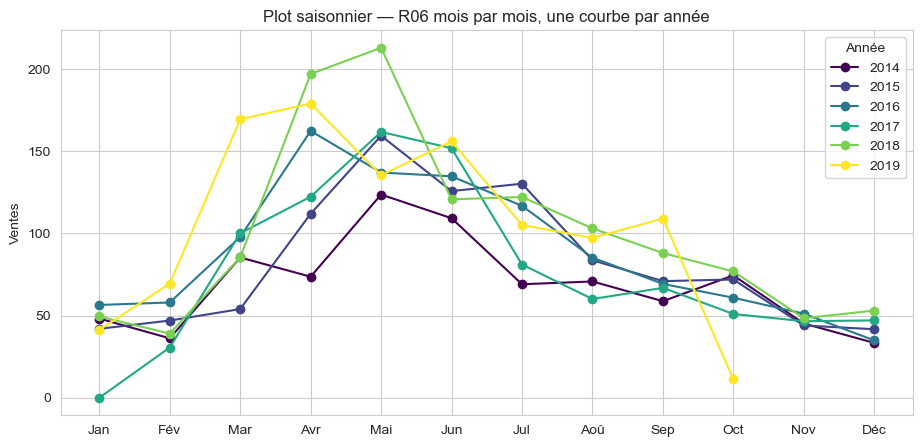

In [9]:
y_seas = df_m['R06'].copy()
y_seas_df = pd.DataFrame({
    'mois': y_seas.index.month,
    'annee': y_seas.index.year,
    'R06': y_seas.values
})
y_pivot = y_seas_df.pivot(index='mois', columns='annee', values='R06')

fig, ax = plt.subplots(figsize=(11, 5))
y_pivot.plot(ax=ax, marker='o', cmap='viridis')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc'])
ax.set_title('Plot saisonnier — R06 mois par mois, une courbe par année')
ax.set_xlabel(''); ax.set_ylabel('Ventes')
ax.legend(title='Année', loc='upper right')
plt.show()

**Lecture :** la **forme** est conservée d'une année à l'autre (saisonnalité reproductible), avec quelques variations d'amplitude. C'est exactement le pattern qu'aiment SARIMA et Prophet.

### 12.5 Lag plot — détecter l'auto-similarité

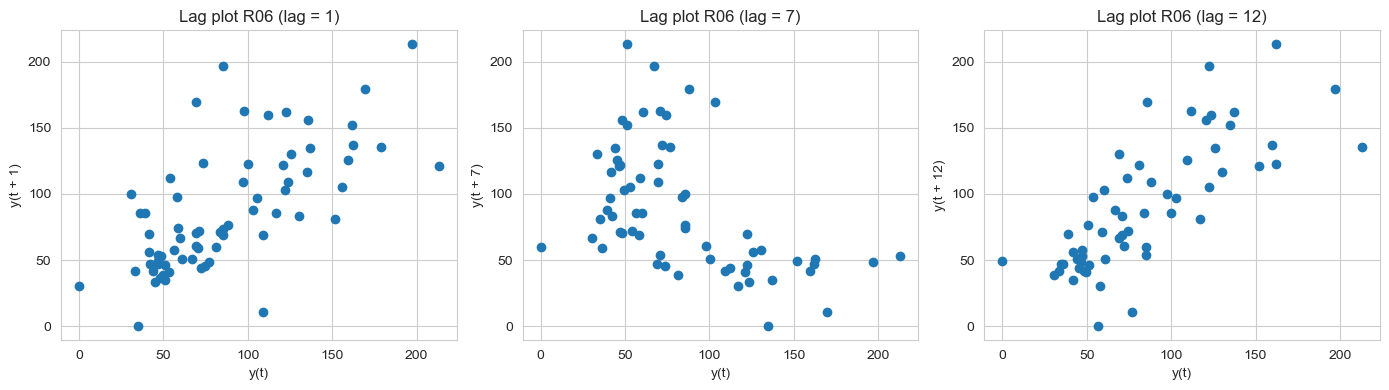

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, lag in zip(axes, [1, 7, 12]):
    pd.plotting.lag_plot(df_m['R06'], lag=lag, ax=ax)
    ax.set_title(f'Lag plot R06 (lag = {lag})')
plt.tight_layout(); plt.show()

**Interprétation :** un nuage aligné sur la diagonale = forte auto-corrélation à ce lag. Le lag 12 (mêmes mois, années différentes) montre une corrélation forte → confirme la saisonnalité annuelle.

---
## Module 13 — Stationnarité \& autocorrélation

### 13.1 Tests ADF et KPSS

**Hypothèses inversées entre ADF et KPSS — les utiliser conjointement.**

| Test | $H_0$ | $H_1$ | $p < 0{,}05$ |
|---|---|---|---|
| ADF | non stationnaire | stationnaire | série stationnaire |
| KPSS | stationnaire | non stationnaire | série non stationnaire |

In [11]:
def test_stationnarite(serie, nom):
    adf_stat, adf_p, *_ = adfuller(serie.dropna())
    try:
        kpss_stat, kpss_p, *_ = kpss(serie.dropna(), regression='c')
    except Exception:
        kpss_stat, kpss_p = float('nan'), float('nan')
    print(f'--- {nom} ---')
    print(f'ADF  : stat = {adf_stat:.3f},  p = {adf_p:.4f}    -> {"stationnaire" if adf_p < 0.05 else "NON stationnaire"}')
    print(f'KPSS : stat = {kpss_stat:.3f},  p = {kpss_p:.4f}    -> {"NON stationnaire" if kpss_p < 0.05 else "stationnaire"}')
    print()

test_stationnarite(df_m['R06'], 'R06 brut')

--- R06 brut ---
ADF  : stat = -1.434,  p = 0.5660    -> NON stationnaire
KPSS : stat = 0.160,  p = 0.1000    -> stationnaire



/var/folders/q2/01kjvnw958g_b78gjjzklwy40000gp/T/ipykernel_89245/1710032030.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(serie.dropna(), regression='c')


**Lecture :** souvent ADF et KPSS donnent des conclusions différentes — c'est à cause de la saisonnalité (qui rend la moyenne périodiquement variable). On va appliquer une **différenciation saisonnière**.

### 13.2 Différenciation

$$\nabla Y_t = Y_t - Y_{t-1} \qquad \nabla_s Y_t = Y_t - Y_{t-s}$$

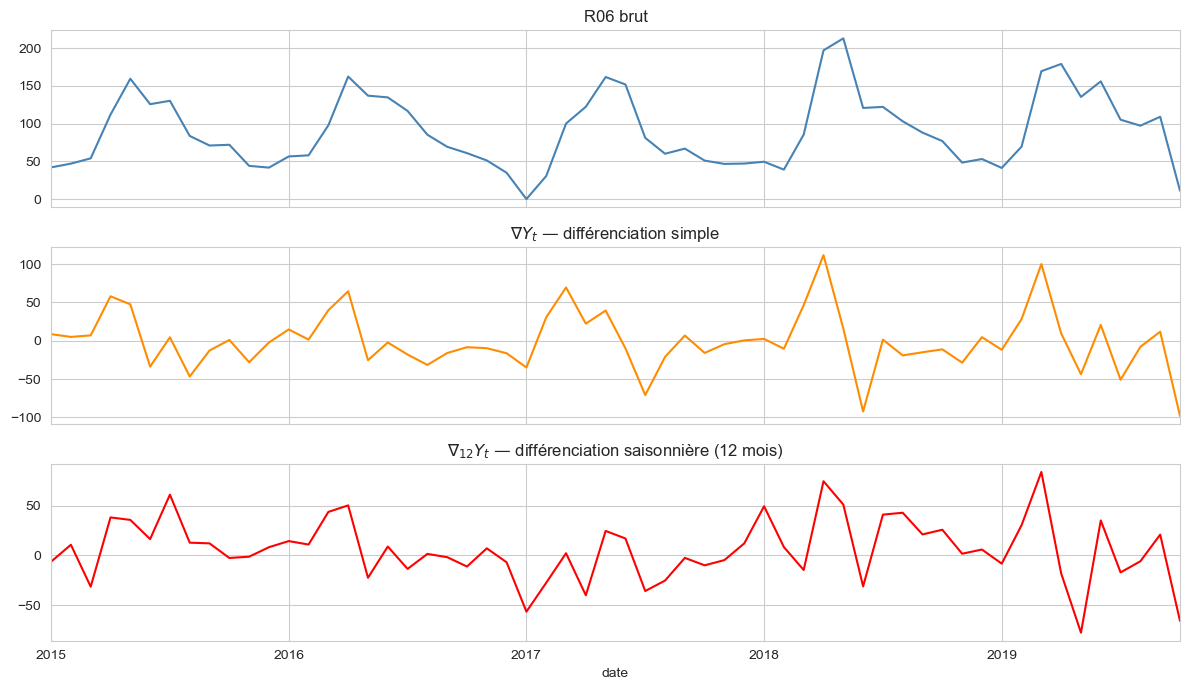

--- R06 après différenciation saisonnière ---
ADF  : stat = -2.931,  p = 0.0419    -> stationnaire
KPSS : stat = 0.134,  p = 0.1000    -> stationnaire



/var/folders/q2/01kjvnw958g_b78gjjzklwy40000gp/T/ipykernel_89245/1710032030.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(serie.dropna(), regression='c')


In [12]:
y_diff   = df_m['R06'].diff().dropna()           # différenciation simple
y_diff12 = df_m['R06'].diff(12).dropna()         # différenciation saisonnière

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
df_m['R06'].plot(ax=axes[0], color='steelblue')
axes[0].set_title('R06 brut')
y_diff.plot(ax=axes[1], color='darkorange')
axes[1].set_title(r'$\nabla Y_t$ — différenciation simple')
y_diff12.plot(ax=axes[2], color='red')
axes[2].set_title(r'$\nabla_{12} Y_t$ — différenciation saisonnière (12 mois)')
plt.tight_layout(); plt.show()

test_stationnarite(y_diff12, 'R06 après différenciation saisonnière')

**Lecture :** après différenciation saisonnière, ADF rejette plus nettement la non-stationnarité. La série est désormais utilisable par un modèle SARIMA.

### 13.3 ACF / PACF

$$\rho(h) = \frac{\mathrm{Cov}(Y_t, Y_{t+h})}{\mathrm{Var}(Y_t)}$$

- **ACF** : auto-corrélation totale au lag $h$.
- **PACF** : auto-corrélation **après** suppression de l'effet des lags intermédiaires.

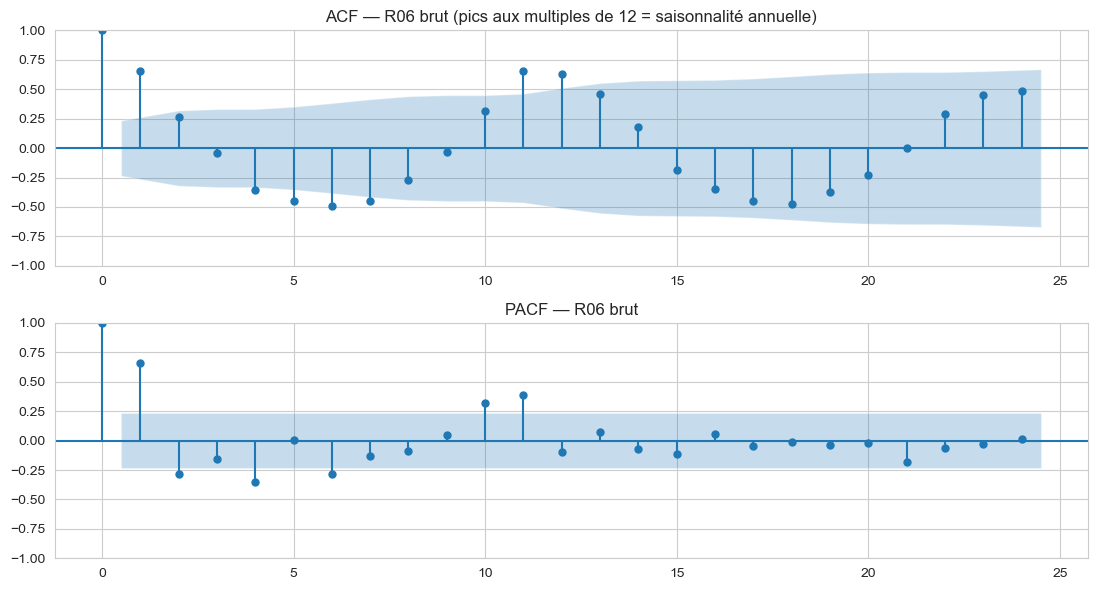

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
plot_acf(df_m['R06'].dropna(),  lags=24, ax=axes[0])
axes[0].set_title('ACF — R06 brut (pics aux multiples de 12 = saisonnalité annuelle)')
plot_pacf(df_m['R06'].dropna(), lags=24, ax=axes[1], method='ywm')
axes[1].set_title('PACF — R06 brut')
plt.tight_layout(); plt.show()

**Interprétation :** des pics ACF aux lags **12, 24** confirment la saisonnalité annuelle. La décroissance lente de l'ACF avant différenciation indique la non-stationnarité.

---
## Module 14 — Modèles de prévision

On va prévoir les 12 derniers mois de R06.
Le passé sert de **train**, le test = la dernière année observée.

In [14]:
y = df_m['R06'].copy()
h = 12  # horizon de prévision : 12 mois

y_train = y.iloc[:-h]
y_test  = y.iloc[-h:]

print(f'Train : {y_train.index.min().date()} -> {y_train.index.max().date()}  ({len(y_train)} mois)')
print(f'Test  : {y_test.index.min().date()} -> {y_test.index.max().date()}  ({len(y_test)} mois)')

Train : 2014-01-31 -> 2018-10-31  (58 mois)
Test  : 2018-11-30 -> 2019-10-31  (12 mois)


### 14.1 Métriques d'évaluation

$$\mathrm{MAE} = \frac{1}{n}\sum |Y_t - \hat{Y}_t| \qquad \mathrm{RMSE} = \sqrt{\frac{1}{n}\sum (Y_t - \hat{Y}_t)^2}$$

$$\mathrm{MAPE} = \frac{100}{n}\sum \left|\frac{Y_t - \hat{Y}_t}{Y_t}\right| \qquad \mathrm{sMAPE} = \frac{100}{n}\sum \frac{2|Y_t - \hat{Y}_t|}{|Y_t| + |\hat{Y}_t|}$$

In [15]:
def metriques(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    err  = y_true - y_pred
    mae  = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err**2))
    mape = 100 * np.mean(np.abs(err) / np.abs(y_true))
    smape = 100 * np.mean(2 * np.abs(err) / (np.abs(y_true) + np.abs(y_pred)))
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'sMAPE': smape}

resultats = {}

### 14.2 Baselines — toujours en premier

Trois baselines à battre :
- **Naïve** : $\hat{Y}_{t+1} = Y_t$
- **Naïve saisonnière** : $\hat{Y}_{t+1} = Y_{t+1-s}$ (même mois l'an passé)
- **Moyenne historique**

In [16]:
# Naïve : on répète la dernière valeur
pred_naive = pd.Series(y_train.iloc[-1], index=y_test.index)

# Naïve saisonnière : on prend la valeur du même mois 12 mois plus tôt
pred_seas  = y_train.iloc[-12:].values
pred_seas  = pd.Series(pred_seas, index=y_test.index)

# Moyenne historique
pred_mean  = pd.Series(y_train.mean(), index=y_test.index)

resultats['Naïve']            = metriques(y_test, pred_naive)
resultats['Naïve saisonnière'] = metriques(y_test, pred_seas)
resultats['Moyenne historique'] = metriques(y_test, pred_mean)

pd.DataFrame(resultats).T.round(2)

,MAE,RMSE,MAPE,sMAPE
Naïve,47.87,56.26,89.54,55.76
Naïve saisonnière,30.91,41.61,70.87,35.57
Moyenne historique,46.63,53.93,96.58,53.99


**Lecture :** sur une série à forte saisonnalité, la **naïve saisonnière** est généralement excellente. Tout modèle complexe doit la battre, sinon il n'apporte rien.

### 14.3 Holt-Winters (lissage exponentiel triple)

Capture niveau + tendance + saisonnalité, avec trois constantes de lissage.

In [17]:
modele_hw = ExponentialSmoothing(
    y_train, seasonal_periods=12,
    trend='add', seasonal='add',
).fit()

pred_hw = modele_hw.forecast(h)
resultats['Holt-Winters'] = metriques(y_test, pred_hw)

pd.DataFrame({'Holt-Winters': resultats['Holt-Winters']}).T.round(2)

,MAE,RMSE,MAPE,sMAPE
Holt-Winters,24.74,33.81,72.28,30.09


### 14.4 SARIMA — manuel et automatique

$$\mathrm{SARIMA}(p, d, q)(P, D, Q, s)$$

On compare un SARIMA tuné à la main avec `auto_arima` qui cherche les meilleurs paramètres.

In [18]:
# SARIMA manuel : ordre raisonnable (1,1,1)(1,1,1,12) souvent un bon point de départ
modele_sarima = SARIMAX(
    y_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
).fit(disp=False)

pred_sarima = modele_sarima.forecast(steps=h)
resultats['SARIMA(1,1,1)(1,1,1,12)'] = metriques(y_test, pred_sarima)

# Auto ARIMA : laisse pmdarima choisir
modele_auto = pm.auto_arima(
    y_train, m=12, seasonal=True,
    suppress_warnings=True, error_action='ignore',
    stepwise=True, trace=False,
)
print(f'auto_arima a choisi : SARIMA{modele_auto.order} x {modele_auto.seasonal_order}')

pred_auto, conf_auto = modele_auto.predict(n_periods=h, return_conf_int=True)
resultats[f'auto_arima'] = metriques(y_test, pred_auto)

pd.DataFrame(resultats).T.round(2)

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


auto_arima a choisi : SARIMA(0, 0, 1) x (0, 1, 1, 12)


,MAE,RMSE,MAPE,sMAPE
Naïve,47.87,56.26,89.54,55.76
Naïve saisonnière,30.91,41.61,70.87,35.57
Moyenne historique,46.63,53.93,96.58,53.99
Holt-Winters,24.74,33.81,72.28,30.09
"SARIMA(1,1,1)(1,1,1,12)",23.02,32.99,67.76,28.52
auto_arima,24.27,33.58,69.45,29.63


**Interprétation :** `auto_arima` explore plusieurs combinaisons et choisit celle qui minimise l'AIC. C'est un bon point de départ pour comparer à un SARIMA tuné à la main. Sur une série très saisonnière, les deux convergent souvent.

### 14.5 Prophet (Meta)

$$Y_t = g(t) + s(t) + h(t) + \varepsilon_t$$

- $g(t)$ : tendance
- $s(t)$ : saisonnalités multiples (Fourier)
- $h(t)$ : jours fériés / événements

Prophet attend un DataFrame avec colonnes `ds` (date) et `y` (valeur).

In [19]:
df_prophet = pd.DataFrame({'ds': y_train.index, 'y': y_train.values})

modele_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                         daily_seasonality=False)
modele_prophet.fit(df_prophet)

future = modele_prophet.make_future_dataframe(periods=h, freq='ME')
fcst = modele_prophet.predict(future)
pred_prophet = fcst.set_index('ds').loc[y_test.index, 'yhat']

resultats['Prophet'] = metriques(y_test, pred_prophet)
pd.DataFrame(resultats).T.round(2)

19:53:56 - cmdstanpy - INFO - Chain [1] start processing
19:53:56 - cmdstanpy - INFO - Chain [1] done processing


,MAE,RMSE,MAPE,sMAPE
Naïve,47.87,56.26,89.54,55.76
Naïve saisonnière,30.91,41.61,70.87,35.57
Moyenne historique,46.63,53.93,96.58,53.99
Holt-Winters,24.74,33.81,72.28,30.09
"SARIMA(1,1,1)(1,1,1,12)",23.02,32.99,67.76,28.52
auto_arima,24.27,33.58,69.45,29.63
Prophet,30.37,40.11,77.80,34.69


### 14.6 Visualisation comparative

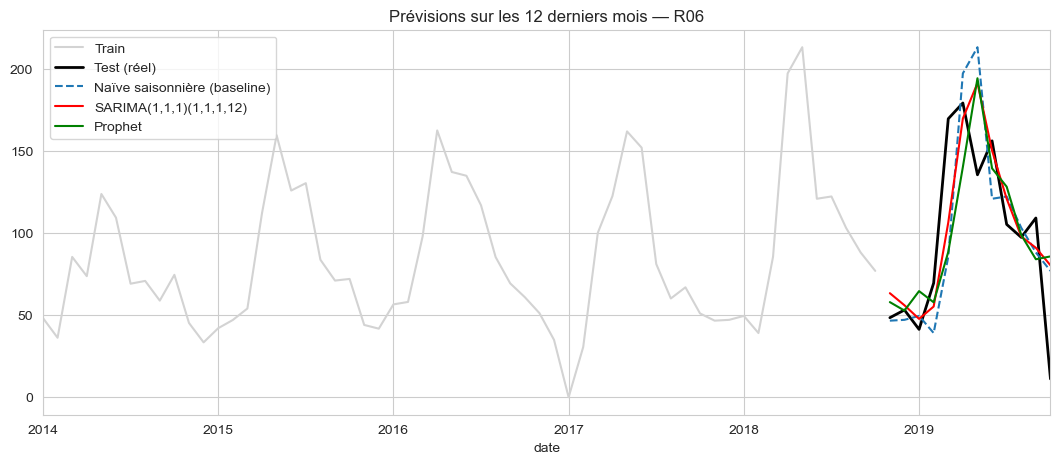

In [20]:
fig, ax = plt.subplots(figsize=(13, 5))
y_train.plot(ax=ax, color='lightgray', label='Train')
y_test.plot(ax=ax, color='black', lw=2, label='Test (réel)')
pred_seas.plot(ax=ax, ls='--', label='Naïve saisonnière (baseline)')
pred_sarima.plot(ax=ax, color='red', label='SARIMA(1,1,1)(1,1,1,12)')
pred_prophet.plot(ax=ax, color='green', label='Prophet')
ax.set_title('Prévisions sur les 12 derniers mois — R06')
ax.legend(); plt.show()

### 14.7 Tableau final des métriques

In [21]:
pd.DataFrame(resultats).T.round(2).sort_values('MAE')

,MAE,RMSE,MAPE,sMAPE
"SARIMA(1,1,1)(1,1,1,12)",23.02,32.99,67.76,28.52
auto_arima,24.27,33.58,69.45,29.63
Holt-Winters,24.74,33.81,72.28,30.09
Prophet,30.37,40.11,77.80,34.69
Naïve saisonnière,30.91,41.61,70.87,35.57
Moyenne historique,46.63,53.93,96.58,53.99
Naïve,47.87,56.26,89.54,55.76


**Lecture :**
- Trier par **MAE** ou **sMAPE** pour comparer (la MAPE explose près de 0 — peu fiable sur des séries pharma à zéros fréquents).
- Tout modèle au-dessus de la naïve saisonnière n'apporte rien.
- Sur R06, SARIMA et Prophet sont généralement comparables. Prophet est plus rapide à mettre en place ; SARIMA donne plus de contrôle.

### 14.8 Intervalles de prédiction

Plus important que la prédiction ponctuelle pour le **stock de sécurité**.

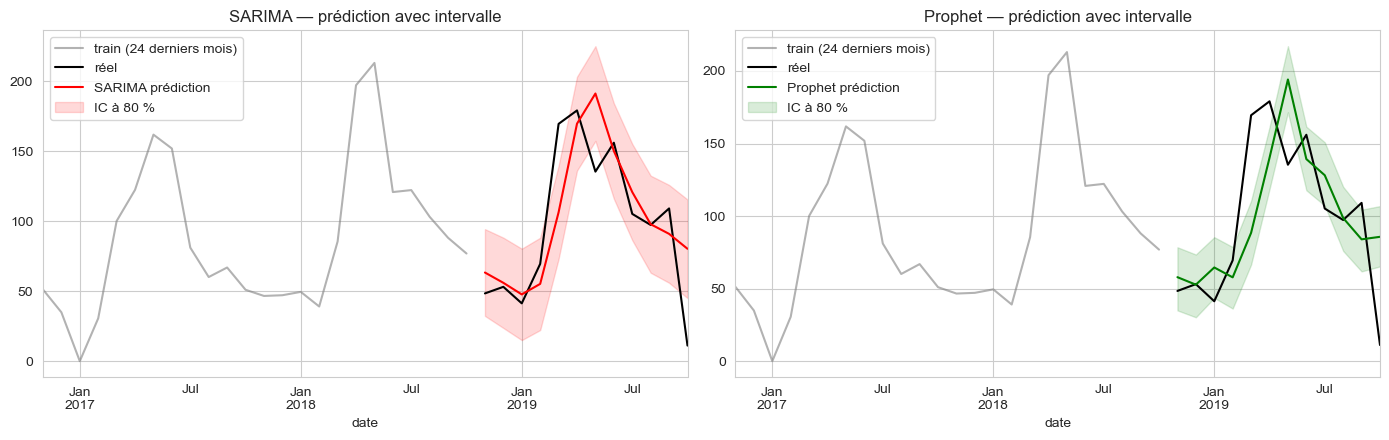

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# SARIMA - intervalle de prédiction
fcst_sarima = modele_sarima.get_forecast(steps=h)
ic_sarima = fcst_sarima.conf_int(alpha=0.20)  # IC à 80 %

ax = axes[0]
y_train.iloc[-24:].plot(ax=ax, color='gray', alpha=0.6, label='train (24 derniers mois)')
y_test.plot(ax=ax, color='black', label='réel')
pred_sarima.plot(ax=ax, color='red', label='SARIMA prédiction')
ax.fill_between(ic_sarima.index, ic_sarima.iloc[:, 0], ic_sarima.iloc[:, 1],
                color='red', alpha=0.15, label='IC à 80 %')
ax.set_title('SARIMA — prédiction avec intervalle')
ax.legend()

# Prophet - intervalle de prédiction
fcst_p_test = fcst.set_index('ds').loc[y_test.index]
ax = axes[1]
y_train.iloc[-24:].plot(ax=ax, color='gray', alpha=0.6, label='train (24 derniers mois)')
y_test.plot(ax=ax, color='black', label='réel')
fcst_p_test['yhat'].plot(ax=ax, color='green', label='Prophet prédiction')
ax.fill_between(fcst_p_test.index, fcst_p_test['yhat_lower'], fcst_p_test['yhat_upper'],
                color='green', alpha=0.15, label='IC à 80 %')
ax.set_title('Prophet — prédiction avec intervalle')
ax.legend()
plt.tight_layout(); plt.show()

**Interprétation :** la largeur de l'intervalle reflète l'incertitude. Pour le **stock de sécurité**, on dimensionne sur la borne supérieure de l'intervalle (par ex. 95 %), pas sur la prédiction ponctuelle.

### 14.9 Backtesting rolling origin

Plutôt qu'un seul split, on simule plusieurs « instants de prédiction » et on agrège.

In [23]:
horizon = 12
min_train = 36   # au moins 3 ans de données pour s=12

errors = []
for t in range(min_train, len(y) - horizon + 1, 6):  # avancer de 6 mois à chaque itération
    train_t = y.iloc[:t]
    test_t  = y.iloc[t:t + horizon]
    try:
        m = SARIMAX(train_t, order=(1,1,1), seasonal_order=(1,1,1,12)).fit(disp=False)
        pred_t = m.forecast(steps=horizon)
        m_dict = metriques(test_t, pred_t)
        m_dict['origin'] = train_t.index[-1].date()
        errors.append(m_dict)
    except Exception as e:
        continue

bt = pd.DataFrame(errors).set_index('origin')
print('Performance SARIMA en backtesting :')
print(bt[['MAE', 'RMSE', 'sMAPE']].round(2))
print()
print('Médiane sur tous les origins :')
print(bt[['MAE', 'RMSE', 'sMAPE']].median().round(2))

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Performance SARIMA en backtesting :
             MAE  RMSE  sMAPE
origin                       
2016-12-31 24.74 31.46  41.03
2017-06-30 24.71 31.10  25.71
2017-12-31 24.64 33.81  24.89
2018-06-30 20.78 28.78  19.53

Médiane sur tous les origins :
MAE     24.67
RMSE    31.28
sMAPE   25.30
dtype: float64


**Interprétation :** la médiane sur plusieurs origines donne une estimation plus fiable de la performance attendue en production qu'un seul split.

---
## Module 15 — Détection d'anomalies

### 15.1 Z-score sur fenêtre roulante

$$z_t = \frac{Y_t - \mu_t^{(k)}}{\sigma_t^{(k)}}$$

**Limite :** sur série saisonnière, signale tous les pics saisonniers comme anomalies.

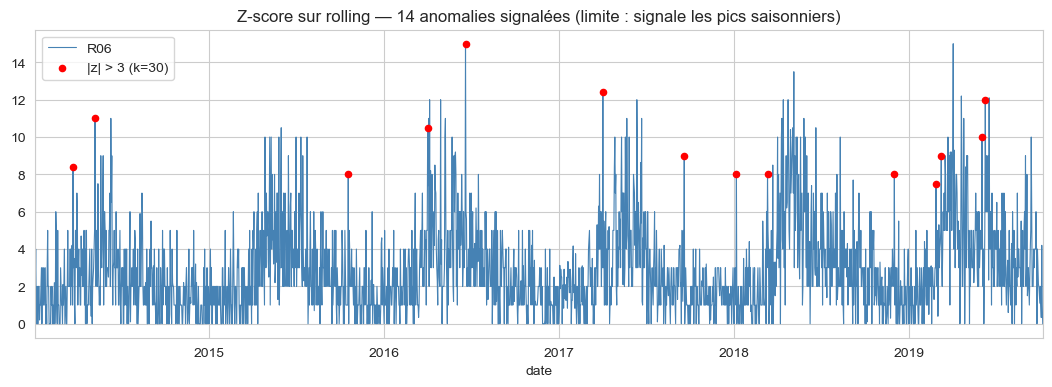

In [24]:
x = df_d['R06']
k = 30
mu_k    = x.rolling(window=k, min_periods=10).mean()
sigma_k = x.rolling(window=k, min_periods=10).std(ddof=1)
z = (x - mu_k) / sigma_k

anomalies = (z.abs() > 3)

fig, ax = plt.subplots(figsize=(13, 4))
x.plot(ax=ax, color='steelblue', lw=0.8, label='R06')
ax.scatter(x.index[anomalies], x[anomalies], color='red', s=20, zorder=5,
           label=f'|z| > 3 (k={k})')
ax.set_title(f'Z-score sur rolling — {anomalies.sum()} anomalies signalées (limite : signale les pics saisonniers)')
ax.legend(); plt.show()

### 15.2 STL + détection sur résidus

Le bon pipeline : décomposer la série, retirer tendance et saisonnalité, et chercher les anomalies sur les **résidus**.

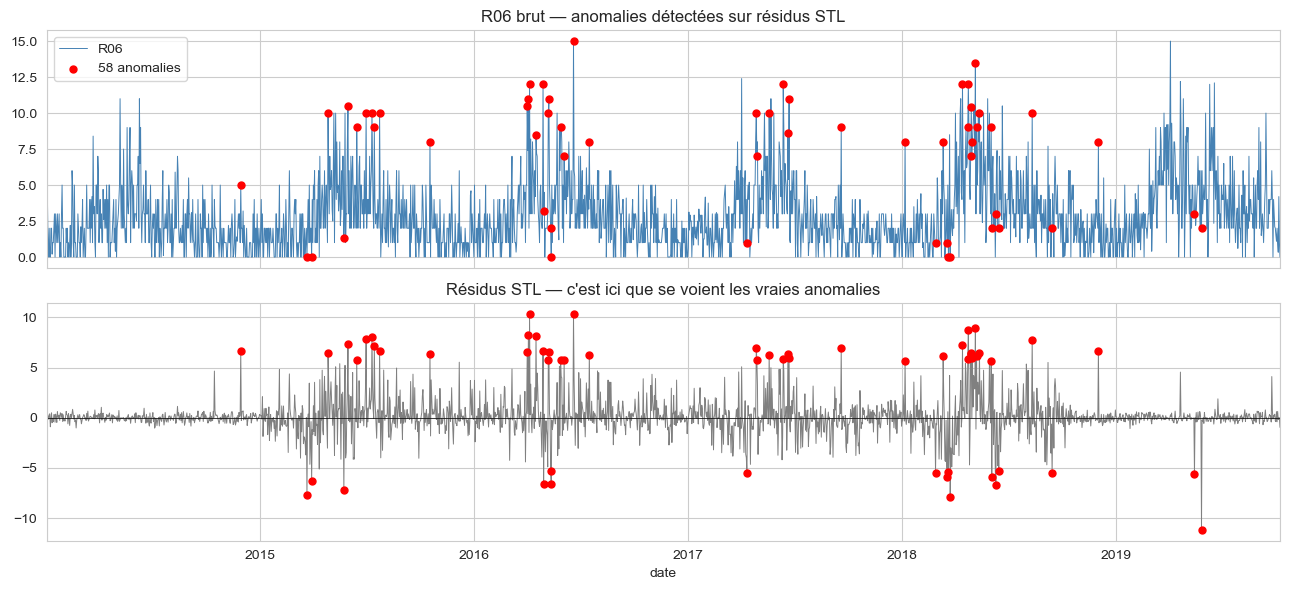

In [25]:
stl = STL(df_d['R06'], period=365, robust=True).fit()
resid = stl.resid

z_resid = (resid - resid.mean()) / resid.std(ddof=1)
anomalies = (z_resid.abs() > 3)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
df_d['R06'].plot(ax=axes[0], color='steelblue', lw=0.7)
axes[0].scatter(df_d.index[anomalies], df_d['R06'][anomalies], color='red',
                s=25, zorder=5, label=f'{anomalies.sum()} anomalies')
axes[0].set_title('R06 brut — anomalies détectées sur résidus STL')
axes[0].legend()

resid.plot(ax=axes[1], color='gray', lw=0.7)
axes[1].scatter(resid.index[anomalies], resid[anomalies], color='red', s=25, zorder=5)
axes[1].axhline(0, color='black', lw=0.5)
axes[1].set_title('Résidus STL — c\'est ici que se voient les vraies anomalies')
plt.tight_layout(); plt.show()

**Comparaison :** la méthode sur résidus signale **beaucoup moins** d'anomalies que le z-score brut, parce qu'elle ne se laisse plus piéger par la saisonnalité. Les anomalies restantes sont des écarts vraiment inattendus, donc *actionnables*.

**À communiquer au métier (cf. slides) :** date, valeur observée vs attendue, sévérité (z-score), contexte connu, action proposée.

---
## Synthèse de la Partie 4

À l'issue de ce TP, vous savez :

- Identifier les composantes d'une série (tendance, saisonnalité, bruit) et choisir entre additif et multiplicatif.
- Préparer une série : index temporel, resampling, valeurs manquantes, lissage (rolling, EWMA).
- Tester la **stationnarité** (ADF, KPSS) et stationnariser (différenciation simple et saisonnière).
- Lire l'**ACF/PACF** pour orienter le choix du modèle.
- Construire des baselines, ajuster un **SARIMA** (manuel + `auto_arima`), un **Prophet**, et les comparer.
- Valider en **split temporel** + backtesting **rolling origin**.
- Choisir la métrique adaptée (MAE/sMAPE plutôt que MAPE).
- Reporter une prédiction **avec son intervalle**.
- Détecter les anomalies via **STL + z-score sur résidus** et communiquer au métier.

### Cheatsheet — formules essentielles

| Concept | Formule |
|---|---|
| Décomposition additive | $Y_t = T_t + S_t + R_t$ |
| Moyenne mobile | $\mathrm{MA}_t^{(k)} = (1/k)\sum_{i=0}^{k-1} Y_{t-i}$ |
| EWMA | $\tilde{Y}_t = \alpha Y_t + (1-\alpha)\tilde{Y}_{t-1}$ |
| Différenciation | $\nabla Y_t = Y_t - Y_{t-1}$ |
| Différenciation saisonnière | $\nabla_s Y_t = Y_t - Y_{t-s}$ |
| ACF | $\rho(h) = \mathrm{Cov}(Y_t, Y_{t+h})/\mathrm{Var}(Y_t)$ |
| Naïve saisonnière | $\hat{Y}_{t+1} = Y_{t+1-s}$ |
| MAE | $(1/n)\sum |Y_t - \hat{Y}_t|$ |
| RMSE | $\sqrt{(1/n)\sum (Y_t - \hat{Y}_t)^2}$ |
| sMAPE | $(100/n)\sum 2|Y_t - \hat{Y}_t|/(|Y_t| + |\hat{Y}_t|)$ |
| SARIMA | $(p,d,q)(P,D,Q,s)$ |
| Prophet | $Y_t = g(t) + s(t) + h(t) + \varepsilon_t$ |

### Suite

Le prochain TP / slides couvre la **Partie 5 — Synthèse \& bonnes pratiques** (Modules 16-17) :
communication des résultats, arbre de décision global « quel outil pour quelle question ».